# D04 — Module de risque : ARCH-LM · GARCH · volatilité prévue · VaR / ES

**Projet :** Quant Lab B09 — DIA

D03 a montré que la moyenne des rendements du DIA est quasi imprévisible, mais que leurs carrés sont fortement autocorrélés (effet ARCH) et que leur loi a des queues épaisses. D04 modélise donc le **risque**, pas la direction. Toute la logique est dans `src/risk.py` et `src/risk_backtest.py` ; ce notebook importe, affiche et trace.

> **Protocole anti-fuite**
> - Paramètres estimés sur l'**apprentissage seul** (2018–2022), puis **gelés** : `arch_model(r_full, ...).fix(params)`, sans ré-estimation.
> - Prévision à **un pas** : la valeur rangée à la date cible t+1 n'utilise que l'information disponible à la clôture t (colonnes `date_prevision`, `date_cible`).
> - Règle de choix **fixée avant** : modèle retenu = plus petit AIC d'apprentissage. La validation (2023–2024) sert à confirmer ; le test (2025–2026) est lu une seule fois.
> - Les baselines (EWMA, écart-type glissant, simulation historique) n'utilisent que des données ≤ t.
>
> **Unités**
> - Rendements r en **% par jour** (100 × rendement log journalier).
> - Volatilité σ en **% par jour** ; annualisée = σ × √252, toujours écrit explicitement.
> - VaR et ES : **perte positive en % par jour**, sur une séance, et en **USD** sur un capital de 100 000 $.
> - Variances réalisées et prévues en %² par jour.

In [128]:
import os
import sys
import warnings
from pathlib import Path

# --- Trouver la racine du projet (contient configs/frozen.yaml) ---
_candidate = Path.cwd()
for _ in range(6):
    if (_candidate / 'configs' / 'frozen.yaml').exists():
        break
    _candidate = _candidate.parent
else:
    raise RuntimeError('Racine du projet introuvable depuis ' + str(Path.cwd()))
root = _candidate
os.chdir(str(root))
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
# -----------------------------------------------------------------

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display

from src.affichage import formater_nombre, formater_tableau, texte_p
from src.data import load_closes, load_ohlcv
from src.features import build_frame, split
from src.models.econometrics import fit_state_space, select_arima_order
from src.risk import (
    correlation_levier, diagnostics_residus_std, fenetres, fit_grid, historical_sigma,
    load_risk_model, mesure_ewma, mesure_historique, mesure_parametrique, modele_retenu,
    parkinson_sigma, qq_points, rendements_pct, residus_standardises, resume_modele,
    resume_var_moyenne, risk_today, rolling_sigma, save_risk_model, tableau_arch_lm,
    tableau_parametres, tableau_risque_date, tableau_temps,
)
from src.risk_backtest import tableau_dm_volatilite, tableau_verification, tableau_volatilite

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.float_format', lambda x: f'{x:.4g}')
pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 90)

with open(root / 'configs' / 'frozen.yaml', encoding='utf-8') as fh:
    CFG = yaml.safe_load(fh)
RCFG = CFG['risk']
CAPITAL = RCFG['capital']

REP_D04 = root / 'reports' / 'd04'
REP_FIG = REP_D04 / 'figures'
REP_FIG.mkdir(parents=True, exist_ok=True)

print('Imports OK')
print('  Rapports :', REP_D04.relative_to(root))
print('  Figures  :', REP_FIG.relative_to(root))
print('  Paramètres risque (frozen.yaml) :', RCFG)

Imports OK
  Rapports : reports\d04
  Figures  : reports\d04\figures
  Paramètres risque (frozen.yaml) : {'scale': 100, 'alphas': [0.05, 0.01], 'models': [{'name': 'GARCH', 'vol': 'GARCH', 'p': 1, 'o': 0, 'q': 1}, {'name': 'GJR-GARCH', 'vol': 'GARCH', 'p': 1, 'o': 1, 'q': 1}, {'name': 'EGARCH', 'vol': 'EGARCH', 'p': 1, 'o': 1, 'q': 1}], 'distributions': ['normal', 't', 'skewt'], 'ewma_lambda': 0.94, 'hs_window': 250, 'rolling_window': 20, 'capital': 100000, 'es_n_sim': 5000, 'seuil_tests': 0.05}


In [129]:
closes = load_closes()
r = rendements_pct(closes)          # % par jour ; la dernière séance du snapshot est conservée
w = fenetres(r)                     # bornes lues dans frozen.yaml
fen_idx = {'validation': w['validation'].index, 'test': w['test'].index}

ohlcv = load_ohlcv()
dia = ohlcv[ohlcv['ticker'] == CFG['tickers']['asset']].set_index('date').sort_index()
sigma_park = parkinson_sigma(dia['high'], dia['low'])   # volatilité RÉALISÉE, % par jour

display(formater_tableau(pd.DataFrame([
    {'fenetre': k, 'premiere date cible': v.index[0].date(), 'derniere date cible': v.index[-1].date(),
     'seances': len(v)}
    for k, v in w.items()
])))

,fenetre,premiere date cible,derniere date cible,seances
0,train,2018-01-03,2022-12-30,1 258
1,validation,2023-01-03,2024-12-31,502
2,test,2025-01-02,2026-10-30,459


## 1. Effet ARCH — test ARCH-LM (Engle, 1982)

**H0** : pas d'effet ARCH (variance conditionnelle constante). Régression de x²_t sur ses 5 ou 10 retards ; LM = n·R² ~ χ²(retards).
Le test porte sur la fenêtre d'**apprentissage**, pour deux séries : les rendements centrés, et les résidus de l'ARIMA retenu en D03 (même règle AIC, même fenêtre).

In [130]:
frame = build_frame(closes)
dec = split(frame)
train_mask = pd.Series(False, index=frame.index)
train_mask.loc[dec['train'].index] = True
ordre_arima = select_arima_order(frame, train_mask)
res_arima = fit_state_space(frame, train_mask, order=ordre_arima)
print('ARIMA retenu en D03 (plus petit AIC sur l’apprentissage) :', res_arima.nom)

df_arch = tableau_arch_lm({
    'Rendements centrés (apprentissage, %)': w['train'] - w['train'].mean(),
    'Résidus ' + res_arima.nom + ' (apprentissage, %)': 100 * res_arima.residuals,
}, lags=(5, 10))
display(formater_tableau(df_arch))

ARIMA retenu en D03 (plus petit AIC sur l’apprentissage) : ARIMA(0,0,3)


,serie,retards,stat_lm,p_value,n,conclusion
0,"Rendements centrés (apprentissage, %)",5,"461,22","< 0,001",1 258,H0 rejetée au seuil 5% : effet ARCH présent
1,"Rendements centrés (apprentissage, %)",10,"515,14","< 0,001",1 258,H0 rejetée au seuil 5% : effet ARCH présent
2,"Résidus ARIMA(0,0,3) (apprentissage, %)",5,"315,56","< 0,001",1 248,H0 rejetée au seuil 5% : effet ARCH présent
3,"Résidus ARIMA(0,0,3) (apprentissage, %)",10,"406,31","< 0,001",1 248,H0 rejetée au seuil 5% : effet ARCH présent


## 2. Asymétrie et grille 3 modèles × 3 lois (apprentissage)

Une baisse est suivie d'une volatilité plus forte qu'une hausse de même taille : sur l'apprentissage, la corrélation entre r_t et |r_{t+1}| vaut −0,113 (p < 0,001, première ligne affichée ci-dessous). Cette asymétrie justifie de comparer au GARCH(1,1) symétrique le GJR-GARCH(1,1,1) et l'EGARCH(1,1,1), chacun avec trois lois standardisées : normale, Student t et Student asymétrique (skewt, Hansen 1994).

**Règle fixée avant de regarder la validation et le test** : modèle retenu = plus petit AIC d'apprentissage parmi les modèles convergés. Le **GARCH(1,1) normal**, référence du cahier, reste dans toutes les comparaisons.

In [131]:
levier = correlation_levier(w['train'])
print('Effet de levier (apprentissage) : corr(r_t, |r_t+1|) =',
      formater_nombre(levier['corr_r_absr_suivant']), '(' + texte_p(levier['pval_absr']) + ') ;',
      '|r_t+1| moyen =', formater_nombre(levier['absr_moyen_apres_baisse_pct'], '_pct'),
      '% après une baisse,', formater_nombre(levier['absr_moyen_apres_hausse_pct'], '_pct'),
      '% après une hausse')

grille, fits = fit_grid(w['train'], CFG)
display(formater_tableau(grille[['modele', 'famille', 'loi', 'aic', 'bic', 'loglik', 'temps_estimation_s', 'converge']]
        .rename(columns={'temps_estimation_s': 'temps estimation (s)'})))

NOM_RETENU = modele_retenu(grille)
NOM_REF = 'GARCH-normal'     # GARCH(1,1) à loi normale, référence du cahier
fit_ret, fit_ref = fits[NOM_RETENU], fits[NOM_REF]
print('Modèle retenu (plus petit AIC sur l’apprentissage) :', NOM_RETENU)
print('Référence du cahier                               :', NOM_REF)

Effet de levier (apprentissage) : corr(r_t, |r_t+1|) = -0,113 (p < 0,001) ; |r_t+1| moyen = 0,97 % après une baisse, 0,78 % après une hausse


,modele,famille,loi,aic,bic,loglik,temps estimation (s),converge
0,EGARCH-skewt,EGARCH,skewt,3 502,3 537,-1 744,"0,053",oui
1,GJR-GARCH-skewt,GJR-GARCH,skewt,3 509,3 545,-1 748,"0,057",oui
2,EGARCH-t,EGARCH,t,3 525,3 555,-1 756,"0,043",oui
3,GJR-GARCH-t,GJR-GARCH,t,3 528,3 559,-1 758,"0,035",oui
4,GARCH-skewt,GARCH,skewt,3 542,3 573,-1 765,"0,045",oui
5,GARCH-t,GARCH,t,3 557,3 583,-1 773,"0,031",oui
6,EGARCH-normal,EGARCH,normal,3 585,3 610,-1 787,"0,031",oui
7,GJR-GARCH-normal,GJR-GARCH,normal,3 591,3 617,-1 791,"0,028",oui
8,GARCH-normal,GARCH,normal,3 622,3 643,-1 807,"0,025",oui


Modèle retenu (plus petit AIC sur l’apprentissage) : EGARCH-skewt
Référence du cahier                               : GARCH-normal


## 3. Lecture du modèle retenu : EGARCH-skewt

Ce tableau montre **comment le modèle voit le risque**. Les paramètres importants sont :

| Paramètre | Rôle | En simple |
|:--|:--|:--|
| **α (alpha)** | Réaction | Un gros choc aujourd'hui fait monter le risque demain |
| **γ (gamma)** | Asymétrie | γ < 0 : une **baisse** fait monter le risque plus qu'une hausse |
| **β (beta)** | Mémoire | Proche de 1 : le risque reste élevé longtemps |
| **η (eta)** | Queues épaisses | Plus il est petit, plus les krachs sont fréquents |
| **λ (lambda)** | Asymétrie de la loi | λ < 0 : les grosses baisses sont plus fréquentes que les grosses hausses |

- **Persistance** (= β pour l'EGARCH) : la mémoire globale du risque.
- **Demi-vie** : nombre de séances pour qu'un choc se calme de moitié.
- μ et ω sont des réglages techniques du modèle, non essentiels ici.

In [132]:
print('Modèle retenu :', NOM_RETENU)
display(formater_tableau(tableau_parametres(fit_ret)))

resume = resume_modele(fit_ret)
resume = resume[resume['indicateur'].str.startswith(
    ('persistance', 'demi-vie', 'volatilité conditionnelle moyenne annualisée'))]
display(formater_tableau(resume.reset_index(drop=True)))

Modèle retenu : EGARCH-skewt


,parametre,valeur,p_value,role,unite
0,mu,"0,020","0,391",moyenne conditionnelle,% par jour
1,omega,"0,008","0,315",constante de variance,%² par jour (EGARCH : ln %²)
2,alpha[1],"0,181","< 0,001",réaction aux chocs,sans unité
3,gamma[1],"-0,169","< 0,001",asymétrie (effet de levier),sans unité
4,beta[1],"0,973","< 0,001",mémoire de la volatilité,sans unité
5,eta,"6,851","< 0,001",degrés de liberté (queues épaisses),sans unité
6,lambda,"-0,205","< 0,001",asymétrie de la loi (Hansen),sans unité


,indicateur,valeur,unite
0,persistance,"0,973",sans unité
1,demi-vie d'un choc,"25,11",séances
2,volatilité conditionnelle moyenne annualisée (× √252),"21,33",% par an


## 4. Diagnostics : le modèle a-t-il tout capté ?

On divise chaque erreur par le risque prévu : on obtient les **résidus standardisés z**.
Si le modèle est bon, z doit être du **pur hasard** : plus de logique (Ljung-Box z), plus d'effet ARCH (Ljung-Box z²).
Le **QQ-plot** vérifie que la loi choisie colle aux données : les points doivent suivre la diagonale.

,test,retards,stat,p_value,conclusion
0,Ljung-Box z,10,"13,06","0,220",H0 non rejetée
1,Ljung-Box z²,10,"19,25","0,037",H0 rejetée
2,Jarque-Bera z,—,"495,06","< 0,001",H0 rejetée


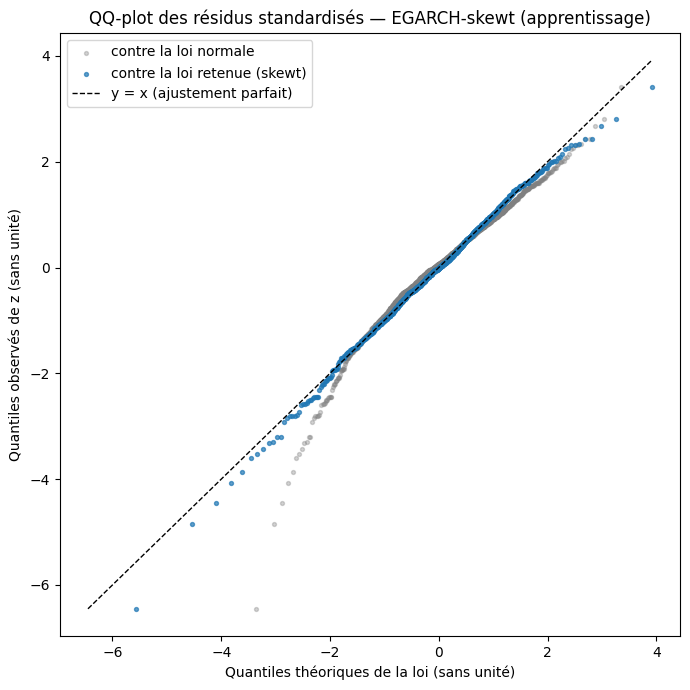

In [133]:
z = residus_standardises(fit_ret['spec'], fit_ret['params'], w['train'])
diag_z = diagnostics_residus_std(z)

# On garde 3 lignes : Ljung-Box z (10), Ljung-Box z² (10), Jarque-Bera
garder = ((diag_z['test'].str.startswith('Ljung-Box') & (diag_z['retards'] == 10))
          | diag_z['test'].str.startswith('Jarque-Bera'))
display(formater_tableau(diag_z[garder].reset_index(drop=True)))

qq = qq_points(z, fit_ret['spec']['dist'], fit_ret['params'])
qq_n = qq_points(z, 'normal', {})
bornes = [min(qq.min().min(), qq_n.min().min()), max(qq.max().max(), qq_n.max().max())]

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(qq_n['theorique'], qq_n['empirique'], s=8, alpha=0.35, color='grey',
           label='contre la loi normale')
ax.scatter(qq['theorique'], qq['empirique'], s=8, alpha=0.7, color='#1f77b4',
           label='contre la loi retenue (' + fit_ret['spec']['dist'] + ')')
ax.plot(bornes, bornes, 'k--', lw=1, label='y = x (ajustement parfait)')
ax.set_xlabel('Quantiles théoriques de la loi (sans unité)')
ax.set_ylabel('Quantiles observés de z (sans unité)')
ax.set_title('QQ-plot des résidus standardisés — ' + NOM_RETENU + ' (apprentissage)')
ax.legend(loc='upper left')
plt.tight_layout()
fig.savefig(REP_FIG / 'qqplot_residus_std.png', dpi=120, bbox_inches='tight')
plt.show()

## 5. Volatilité prévue contre réalité (2023–2026)

Chaque jour, le modèle prévoit **la veille** de combien le DIA va bouger (σ, en % par jour).
On compare cette prévision au **mouvement réel** du jour (|r|, en gris).
La ligne pointillée marque le début du test (2025).

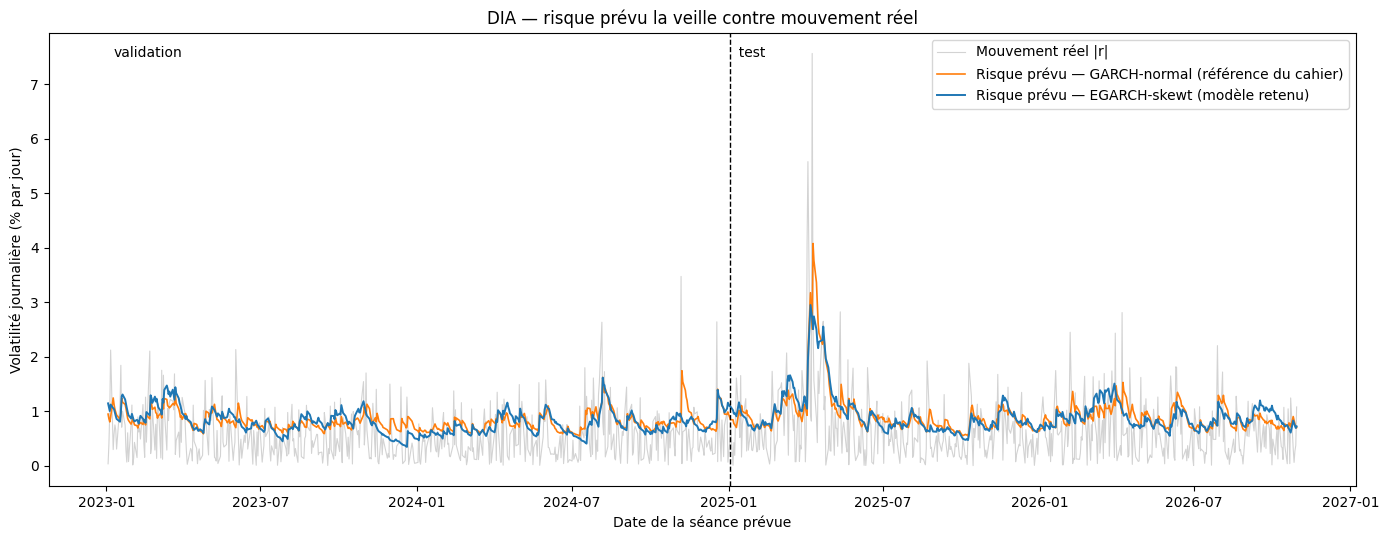

In [134]:
m_ret = mesure_parametrique(r, fit_ret)
m_ref = mesure_parametrique(r, fit_ref)
m_ewma = mesure_ewma(r)
m_hs = mesure_historique(r)

idx_vt = fen_idx['validation'].append(fen_idx['test'])
debut_test = fen_idx['test'][0]

fig, ax = plt.subplots(figsize=(14, 5.5))
ax.plot(idx_vt, r.reindex(idx_vt).abs(), color='lightgrey', lw=0.8,
        label='Mouvement réel |r|')
ax.plot(idx_vt, m_ref['serie']['sigma_pct'].reindex(idx_vt), color='#ff7f0e', lw=1.2,
        label='Risque prévu — ' + NOM_REF + ' (référence du cahier)')
ax.plot(idx_vt, m_ret['serie']['sigma_pct'].reindex(idx_vt), color='#1f77b4', lw=1.4,
        label='Risque prévu — ' + NOM_RETENU + ' (modèle retenu)')
ax.axvline(debut_test, color='black', ls='--', lw=1)
ax.text(fen_idx['validation'][5], 0.97, 'validation', transform=ax.get_xaxis_transform(), va='top')
ax.text(debut_test, 0.97, '  test', transform=ax.get_xaxis_transform(), va='top')
ax.set_xlabel('Date de la séance prévue')
ax.set_ylabel('Volatilité journalière (% par jour)')
ax.set_title('DIA — risque prévu la veille contre mouvement réel')
ax.legend(loc='upper right')
plt.tight_layout()
fig.savefig(REP_FIG / 'volatilite_prevue.png', dpi=120, bbox_inches='tight')
plt.show()

## 6. VaR et ES à 95 % et 99 % — violations

Rendement réalisé, −VaR et −ES prévues par le modèle retenu (en % par jour, sur une séance). Une **violation** est un jour où la perte dépasse la VaR (r < −VaR) ; elles sont en rouge. Sous un modèle correct, on attend 5 % de violations à 95 % et 1 % à 99 %.

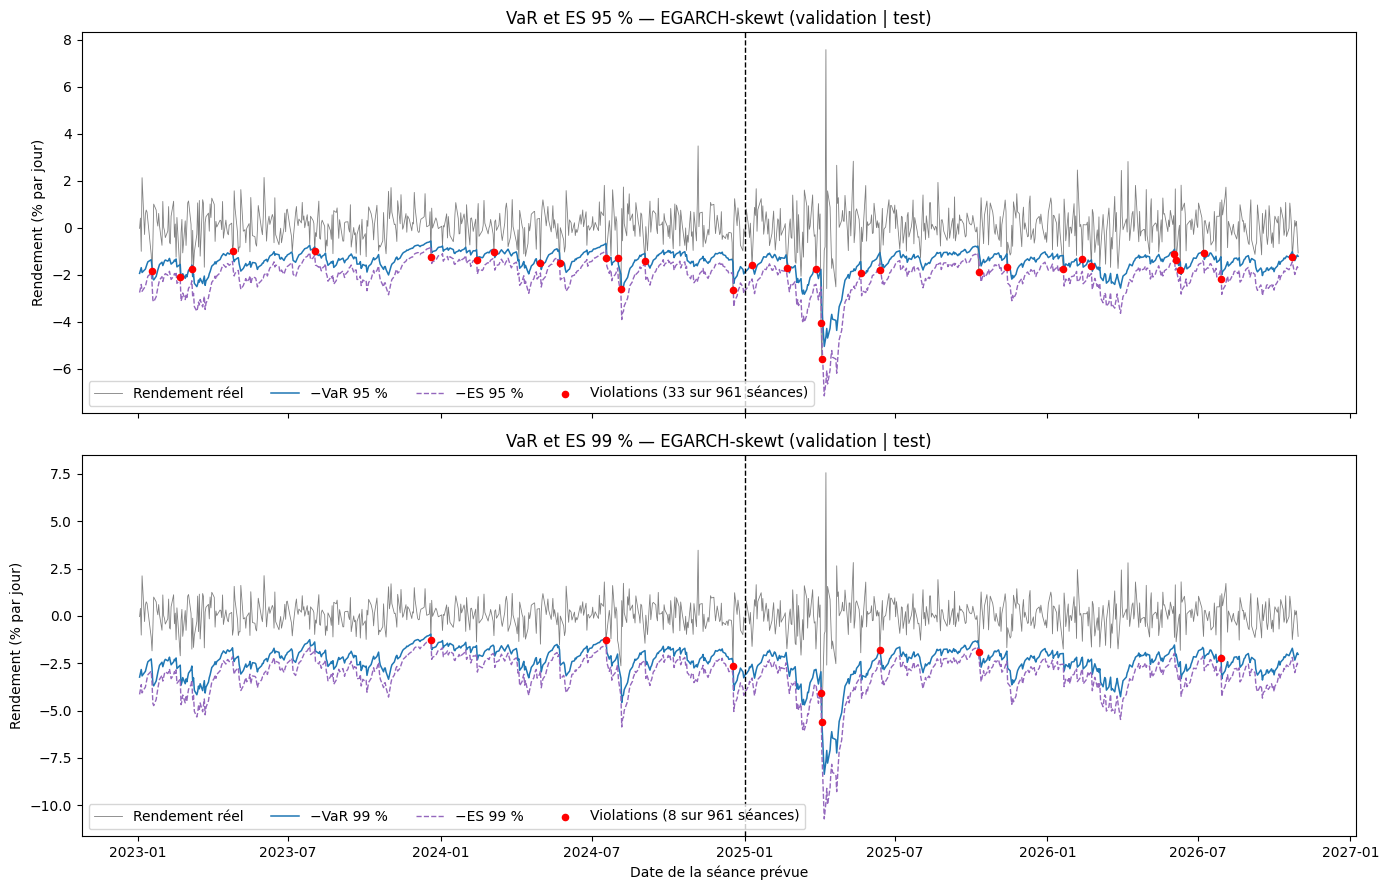

VaR et ES moyennes du modèle retenu (perte sur une séance, capital de 100 000 $) :


,fenetre,niveau,VAR (%),VAR ($),ES (%),ES ($)
0,validation,95,"1,35",1 340,"1,92",1 898
1,validation,99,"2,24",2 215,"2,88",2 834
2,test,95,"1,58",1 566,"2,24",2 214
3,test,99,"2,62",2 583,"3,36",3 301


In [135]:
s_vt = m_ret['serie'].reindex(idx_vt)
r_vt = r.reindex(idx_vt)

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
for ax, niv in zip(axes, (95, 99)):
    viol = (r_vt < -s_vt[f'var{niv}_pct']).to_numpy()
    ax.plot(idx_vt, r_vt, color='grey', lw=0.6, label='Rendement réel')
    ax.plot(idx_vt, -s_vt[f'var{niv}_pct'], color='#1f77b4', lw=1.1, label=f'−VaR {niv} %')
    ax.plot(idx_vt, -s_vt[f'es{niv}_pct'], color='#9467bd', lw=1.0, ls='--', label=f'−ES {niv} %')
    ax.scatter(idx_vt[viol], r_vt[viol], color='red', s=20, zorder=3,
               label=f'Violations ({int(viol.sum())} sur {len(idx_vt)} séances)')
    ax.axvline(debut_test, color='black', ls='--', lw=1)
    ax.set_ylabel('Rendement (% par jour)')
    ax.set_title(f'VaR et ES {niv} % — ' + NOM_RETENU + ' (validation | test)')
    ax.legend(loc='lower left', ncol=4)
axes[-1].set_xlabel('Date de la séance prévue')
plt.tight_layout()
fig.savefig(REP_FIG / 'var_es_violations.png', dpi=120, bbox_inches='tight')
plt.show()

print('VaR et ES moyennes du modèle retenu (perte sur une séance, capital de 100 000 $) :')
t = resume_var_moyenne(m_ret['serie'], fen_idx)
p = t.pivot_table(index=['fenetre', 'niveau'], columns='mesure',
                  values=['moyenne_pct', 'moyenne_usd'], sort=False)
p.columns = [m + (' (%)' if v == 'moyenne_pct' else ' ($)') for v, m in p.columns]
p = p.reset_index()[['fenetre', 'niveau', 'VAR (%)', 'VAR ($)', 'ES (%)', 'ES ($)']]
display(formater_tableau(p))

## 7. La VaR est-elle juste ? Vérification sur 2023–2026

On compare 4 méthodes : notre modèle (EGARCH-skewt), le GARCH normal du cahier, l'EWMA (RiskMetrics) et la simulation historique (250 jours).
Une bonne VaR doit passer **3 tests** (p > 0,05 = test réussi) :

- **Kupiec** : le **nombre** de violations est-il correct (5 % à 95 %, 1 % à 99 %) ?
- **Christoffersen** : les violations sont-elles **dispersées**, et pas groupées ?
- **Acerbi-Székely** : l'**ES** n'est-il pas trop optimiste ?

In [136]:
verif = tableau_verification(r, [m_ret, m_ref, m_ewma, m_hs], fen_idx)
colonnes = ['modele', 'violations', 'taux_observe_pct', 'kupiec_p',
            'christoffersen_ind_p', 'z2_p', 'conclusion']
noms = {'taux_observe_pct': 'taux observé (%)', 'kupiec_p': 'Kupiec p (nombre)',
        'christoffersen_ind_p': 'Christoffersen p (groupées ?)', 'z2_p': 'ES p (Acerbi-Székely)'}
attendu = {95: 5, 99: 1}
for fen in fen_idx:
    for niv in (95, 99):
        n = int(verif[(verif['fenetre'] == fen) & (verif['niveau'] == niv)]['jours'].iloc[0])
        print(f'{fen.capitalize()} — VaR {niv} % ({n} séances, {attendu[niv]} % de violations attendues)')
        t = verif[(verif['fenetre'] == fen) & (verif['niveau'] == niv)][colonnes].rename(columns=noms)
        display(formater_tableau(t.reset_index(drop=True)))

Validation — VaR 95 % (502 séances, 5 % de violations attendues)


,modele,violations,taux observé (%),Kupiec p (nombre),Christoffersen p (groupées ?),ES p (Acerbi-Székely),conclusion
0,EGARCH-skewt,15,"2,99","0,026","0,336","0,987",rejetée : taux de violation rejeté (Kupiec)
1,GARCH-normal,23,"4,58","0,663","0,137","0,673",validée
2,EWMA,29,"5,78","0,435","0,798","0,166",validée
3,Simulation historique (250 j),17,"3,39","0,079","0,122","0,925",validée


Validation — VaR 99 % (502 séances, 1 % de violations attendues)


,modele,violations,taux observé (%),Kupiec p (nombre),Christoffersen p (groupées ?),ES p (Acerbi-Székely),conclusion
0,EGARCH-skewt,3,"0,60","0,327","0,849","0,840",validée
1,GARCH-normal,5,"1,00","0,993","0,751","0,426",validée
2,EWMA,6,"1,20","0,670","0,703","0,240",validée
3,Simulation historique (250 j),6,"1,20","0,670","0,054","0,272",validée


Test — VaR 95 % (459 séances, 5 % de violations attendues)


,modele,violations,taux observé (%),Kupiec p (nombre),Christoffersen p (groupées ?),ES p (Acerbi-Székely),conclusion
0,EGARCH-skewt,18,"3,92","0,271","0,732","0,861",validée
1,GARCH-normal,25,"5,45","0,665","0,766","0,150",validée
2,EWMA,25,"5,45","0,665","0,551","0,118",validée
3,Simulation historique (250 j),26,"5,66","0,522","0,663","0,285",validée


Test — VaR 99 % (459 séances, 1 % de violations attendues)


,modele,violations,taux observé (%),Kupiec p (nombre),Christoffersen p (groupées ?),ES p (Acerbi-Székely),conclusion
0,EGARCH-skewt,5,"1,09","0,850","0,038","0,493",rejetée : violations groupées (Christoffersen)
1,GARCH-normal,8,"1,74","0,148","0,120","0,033",rejetée : ES trop optimiste (Z2)
2,EWMA,8,"1,74","0,148","0,120","0,016",rejetée : ES trop optimiste (Z2)
3,Simulation historique (250 j),7,"1,53","0,294","0,087","0,152",validée


## 8. Quel modèle prévoit le mieux le risque ?

On donne à chaque modèle un **score d'erreur**, le **QLIKE** : il compare le risque prévu la veille au mouvement réel du jour.
**Plus le score est petit, meilleure est la prévision.** Le QLIKE punit surtout le fait de **sous-estimer** le risque, l'erreur la plus dangereuse.

In [137]:
NOM_GLISS = 'Glissante ' + str(RCFG['rolling_window']) + ' j'
sigmas = {
    NOM_RETENU: m_ret['serie']['sigma_pct'],
    NOM_REF: m_ref['serie']['sigma_pct'],
    'EWMA': m_ewma['serie']['sigma_pct'],
    NOM_GLISS: rolling_sigma(r),
    'Écart-type historique': historical_sigma(r),
}
realisees = {'r²': r ** 2, 'Parkinson²': sigma_park ** 2}

eval_vol = tableau_volatilite(sigmas, realisees, fen_idx)        # détail en annexe
dm_vol = tableau_dm_volatilite(sigmas, realisees, fen_idx, reference=NOM_RETENU,
                               concurrents=['EWMA', NOM_GLISS, NOM_REF])   # détail en annexe

print('QLIKE moyenne contre r² (sans unité, plus petite = meilleure), triée sur le test :')
display(formater_tableau(eval_vol[eval_vol['mesure_realisee'] == 'r²']
        .pivot(index='modele', columns='fenetre', values='qlike_moyen')[['validation', 'test']]
        .sort_values('test')))

QLIKE moyenne contre r² (sans unité, plus petite = meilleure), triée sur le test :


fenetre,validation,test
modele,,
EGARCH-skewt,"0,369","0,644"
GARCH-normal,"0,367","0,686"
EWMA,"0,357","0,730"
Glissante 20 j,"0,399","0,792"
Écart-type historique,"0,820","0,984"


## 9. Coût de calcul (axe B09)

Temps pour **estimer** le modèle (sur 2018–2022) et **prévoir** le risque de chaque jour (sur toute la série), en secondes.
Les méthodes simples (EWMA, glissante, simulation historique) n'ont rien à estimer.

In [138]:
temps = tableau_temps(fits, r)
garder = [NOM_RETENU, NOM_REF, 'EWMA', NOM_GLISS, 'Simulation historique (250 j)']
temps = temps[temps['modele'].isin(garder)].reset_index(drop=True)
display(formater_tableau(temps.rename(columns={'estimation_s': 'estimation (s)',
                                               'prevision_s': 'prévision (s)',
                                               'total_s': 'total (s)'})).style.hide(axis='index'))

modele,estimation (s),prévision (s),total (s)
EGARCH-skewt,"0,053","0,005","0,058"
GARCH-normal,"0,025","0,009","0,034"
Simulation historique (250 j),"0,000","0,029","0,029"
EWMA,"0,000","0,005","0,005"
Glissante 20 j,"0,000","0,004","0,004"


## 9b. Le risque de demain, comme dans l'application

Le modèle retenu est **sauvegardé** dans `models/risk_params.json`.
L'application, la stratégie (D06) et le paper trading (D08) le rechargent **sans le ré-estimer**.
La fonction `risk_today` donne le risque de la **prochaine séance** :

In [139]:
chemin_modele = save_risk_model(fit_ret['spec'], fit_ret['params'])
demain = risk_today(r, chemin_modele)

date_prev = pd.Timestamp(demain['date_prevision']).date()
date_cible = pd.Timestamp(demain['date_cible']).date()

print(f"Modèle sauvegardé : {chemin_modele.relative_to(root)}  ({demain['modele']})")
print(f"Prévision faite le {date_prev} pour la séance du {date_cible} :")

tab = pd.DataFrame({
    'Mesure': ['Volatilité prévue σ', 'VaR 95 %', 'ES 95 %', 'VaR 99 %', 'ES 99 %'],
    '% par jour': [f"{demain[k]:.2f} %".replace('.', ',') for k in
                   ['sigma_pct', 'var95_pct', 'es95_pct', 'var99_pct', 'es99_pct']],
    'Perte sur 100 000 $': ['—'] + [f"{demain[k]:,.0f} $".replace(',', ' ') for k in
                                    ['var95_usd', 'es95_usd', 'var99_usd', 'es99_usd']],
})
display(tab.style.hide(axis='index'))

Modèle sauvegardé : models\risk_params.json  (EGARCH-skewt)
Prévision faite le 2026-10-30 pour la séance du 2026-11-02 :


Mesure,% par jour,Perte sur 100 000 $
Volatilité prévue σ,"0,89 %",—
VaR 95 %,"1,51 %",1 495 $
ES 95 %,"2,14 %",2 116 $
VaR 99 %,"2,50 %",2 470 $
ES 99 %,"3,21 %",3 159 $


### Annexe technique — export des résultats
Génère les fichiers CSV de `reports/d04/` (livrables). Non présenté à l'oral.

In [ ]:
risque_date = tableau_risque_date(r, m_ret['serie'], sigma_park, fen_idx)
exports = {
    'arch_lm.csv': df_arch,
    'grille_modeles.csv': grille,
    'parametres_retenu.csv': tableau_parametres(fit_ret),
    'diagnostics_residus_std.csv': diag_z,
    'verification_var_es.csv': verif,
    'eval_volatilite.csv': eval_vol,
    'dm_volatilite.csv': dm_vol,
    'temps_calcul.csv': tableau_temps(fits, r),
    'risque_date.csv': risque_date,
}
for nom, df in exports.items():
    df.to_csv(REP_D04 / nom, index=False)
print(f'{len(exports)} fichiers CSV exportés dans reports/d04/')

print('Aperçu de risque_date.csv (la prévision est toujours faite la veille) :')
apercu = risque_date[['date_prevision', 'date_cible', 'rendement_realise_pct',
                      'sigma_pct', 'var95_pct', 'var95_usd', 'violation95']]
display(formater_tableau(apercu.head()).style.hide(axis='index'))

9 fichiers CSV exportés dans reports/d04/
Aperçu de risque_date.csv (la prévision est toujours faite la veille) :


date_prevision,date_cible,rendement_realise_pct,sigma_pct,var95_pct,var95_usd,violation95
2022-12-30,2023-01-03,"-0,03","1,14","1,95",1 928,0
2023-01-03,2023-01-04,"0,40","1,07","1,83",1 809,0
2023-01-04,2023-01-05,"-1,01","1,00","1,70",1 690,0
2023-01-05,2023-01-06,"2,12","1,12","1,91",1 891,0
2023-01-06,2023-01-09,"-0,29","1,06","1,80",1 780,0


## 11. Conclusion

1. **Le risque se prévoit.** L'effet ARCH est confirmé (p < 0,001) : la direction est imprévisible (D03), mais pas l'ampleur des mouvements.
2. **Modèle retenu : EGARCH-skewt** (meilleur AIC). Le marché réagit plus fort aux baisses (γ = −0,17), et les krachs sont plus fréquents qu'avec une loi normale.
3. **Longue mémoire.** Un choc met environ **25 séances (5 semaines)** à se calmer de moitié.
4. **Résidus presque propres.** Plus de logique dans les erreurs ; il ne reste qu'un petit effet ARCH.
5. **VaR validée dans 2 cas sur 4** : trop prudente en 2023–2024, violations groupées en avril 2025. Mais son **ES n'est jamais trop optimiste**, contrairement aux modèles à loi normale.
6. **Simple contre complexe (B09).** Pour la **VaR**, la simulation historique (sans paramètre) fait aussi bien. Pour **prévoir la volatilité**, l'EGARCH est le meilleur sur le test. Le coût de calcul est négligeable.
7. **Lien avec D06.** `risk_today` donne le risque du lendemain (VaR 95 % ≈ 1 495 $ pour le 2 novembre 2026), pour **réduire la position quand le risque monte**.

**Limites :** paramètres gelés sur 2018–2022 (avec le COVID), horizon d'une seule séance, risque mesuré de clôture à clôture alors que D06 achète à l'ouverture.

## Annexe — analyses complémentaires

### Qualité de la volatilité prévue : MSE, Parkinson², Mincer-Zarnowitz, Diebold-Mariano

Pertes moyennes **QLIKE** (Patton, 2011, forme RV/h + ln h : plus petit = meilleur, robuste au bruit de la mesure réalisée) et **MSE** (%⁴), contre deux variances réalisées : r² et Parkinson² (%² par jour). Tous les modèles sont comparés sur les mêmes dates.
**Mincer-Zarnowitz** : RV = a + b·σ² ; une prévision sans biais a a = 0 et b = 1 (`mz_p` = p-value du test joint, écarts-types de Newey-West). Parkinson² est structurellement plus basse que r² (elle ignore l'écart de nuit). QLIKE et MSE étant minimales quand la prévision égale l'espérance de la mesure réalisée, une mesure biaisée vers le bas favorise les prévisions de niveau bas : les classements contre Parkinson² sont donc donnés à titre indicatif, et la **référence est r²**, sans biais mais bruitée.
**Diebold-Mariano** sur les pertes QLIKE (variance de Newey-West, correction HLN) : modèle retenu contre EWMA, contre l'écart-type glissant et contre le GARCH normal ; `mean_d` < 0 = modèle retenu meilleur.

In [141]:
for fen in fen_idx:
    for rv in realisees:
        print(f'=== Fenêtre {fen} — variance réalisée {rv} (%² par jour) ===')
        display(formater_tableau(eval_vol[(eval_vol['fenetre'] == fen) & (eval_vol['mesure_realisee'] == rv)]
                .drop(columns=['fenetre', 'mesure_realisee']).sort_values('qlike_moyen')
                .reset_index(drop=True)))

print('=== Diebold-Mariano sur QLIKE ===')
display(formater_tableau(dm_vol))

=== Fenêtre validation — variance réalisée r² (%² par jour) ===


,modele,qlike_moyen,mse_moyen,mz_a,mz_b,mz_r2,mz_p,n
0,EWMA,"0,357","0,913","0,347","0,315","0,005","< 0,001",502
1,GARCH-normal,"0,367","0,993","0,382","0,191","0,004","< 0,001",502
2,EGARCH-skewt,"0,369","0,952","0,240","0,402","0,027","< 0,001",502
3,Glissante 20 j,"0,399","0,930","0,386","0,246","0,005","< 0,001",502
4,Écart-type historique,"0,820","2,245","0,346","0,100","0,000","< 0,001",502


=== Fenêtre validation — variance réalisée Parkinson² (%² par jour) ===


,modele,qlike_moyen,mse_moyen,mz_a,mz_b,mz_r2,mz_p,n
0,EWMA,"0,031","0,179","0,140","0,430","0,061","< 0,001",502
1,Glissante 20 j,"0,046","0,201","0,225","0,274","0,036","< 0,001",502
2,EGARCH-skewt,"0,093","0,281","0,111","0,376","0,146","< 0,001",502
3,GARCH-normal,"0,119","0,299","0,174","0,279","0,058","< 0,001",502
4,Écart-type historique,"0,730","1,849","-0,231","0,358","0,012","< 0,001",502


=== Fenêtre test — variance réalisée r² (%² par jour) ===


,modele,qlike_moyen,mse_moyen,mz_a,mz_b,mz_r2,mz_p,n
0,EGARCH-skewt,"0,644","9,224","-0,299","1,206","0,147","0,120",459
1,GARCH-normal,"0,686","10,27","0,259","0,618","0,075","0,215",459
2,EWMA,"0,730","10,42","0,288","0,671","0,039","0,123",459
3,Glissante 20 j,"0,792","11,10","0,537","0,390","0,023","< 0,001",459
4,Écart-type historique,"0,984","11,04","-7,319","5,650","0,006","< 0,001",459


=== Fenêtre test — variance réalisée Parkinson² (%² par jour) ===


,modele,qlike_moyen,mse_moyen,mz_a,mz_b,mz_r2,mz_p,n
0,EGARCH-skewt,"0,337","2,112","-0,451","1,059","0,383","< 0,001",459
1,GARCH-normal,"0,344","2,919","-0,023","0,603","0,241","< 0,001",459
2,EWMA,"0,362","3,161","0,096","0,554","0,091","< 0,001",459
3,Glissante 20 j,"0,366","3,825","0,298","0,327","0,054","0,002",459
4,Écart-type historique,"0,780","3,887","-5,563","4,238","0,012","< 0,001",459


=== Diebold-Mariano sur QLIKE ===


,fenetre,mesure_realisee,comparaison,dm_stat,pval,mean_d,n,conclusion
0,validation,r²,EGARCH-skewt vs EWMA,"0,263","0,793","0,012",502,pas de différence significative
1,validation,r²,EGARCH-skewt vs Glissante 20 j,"-0,713","0,476","-0,030",502,pas de différence significative
2,validation,r²,EGARCH-skewt vs GARCH-normal,"0,044","0,965","0,002",502,pas de différence significative
3,validation,Parkinson²,EGARCH-skewt vs EWMA,"2,958","0,003","0,063",502,EWMA meilleur
4,validation,Parkinson²,EGARCH-skewt vs Glissante 20 j,"1,987","0,047","0,047",502,Glissante 20 j meilleur
5,validation,Parkinson²,EGARCH-skewt vs GARCH-normal,"-1,287","0,199","-0,026",502,pas de différence significative
6,test,r²,EGARCH-skewt vs EWMA,"-2,006","0,045","-0,086",459,EGARCH-skewt meilleur
7,test,r²,EGARCH-skewt vs Glissante 20 j,"-2,611","0,009","-0,147",459,EGARCH-skewt meilleur
8,test,r²,EGARCH-skewt vs GARCH-normal,"-2,007","0,045","-0,042",459,EGARCH-skewt meilleur
9,test,Parkinson²,EGARCH-skewt vs EWMA,"-0,797","0,426","-0,025",459,pas de différence significative


## Références

- Acerbi, C. & Székely, B. (2014). Backtesting Expected Shortfall. *Risk*, décembre 2014.
- Bollerslev, T. (1986). Generalized autoregressive conditional heteroskedasticity. *Journal of Econometrics*, 31(3), 307–327.
- Christoffersen, P. F. (1998). Evaluating interval forecasts. *International Economic Review*, 39(4), 841–862.
- Engle, R. F. (1982). Autoregressive conditional heteroscedasticity with estimates of the variance of United Kingdom inflation. *Econometrica*, 50(4), 987–1007.
- Glosten, L. R., Jagannathan, R. & Runkle, D. E. (1993). On the relation between the expected value and the volatility of the nominal excess return on stocks. *Journal of Finance*, 48(5), 1779–1801.
- Hansen, B. E. (1994). Autoregressive conditional density estimation. *International Economic Review*, 35(3), 705–730.
- J.P. Morgan / Reuters (1996). *RiskMetrics — Technical Document*, 4e édition.
- Kupiec, P. H. (1995). Techniques for verifying the accuracy of risk measurement models. *Journal of Derivatives*, 3(2), 73–84.
- Nelson, D. B. (1991). Conditional heteroskedasticity in asset returns: a new approach. *Econometrica*, 59(2), 347–370.
- Parkinson, M. (1980). The extreme value method for estimating the variance of the rate of return. *Journal of Business*, 53(1), 61–65.
- Patton, A. J. (2011). Volatility forecast comparison using imperfect volatility proxies. *Journal of Econometrics*, 160(1), 246–256.